# Multiple Linear Regression from Scratch

- Multiple Linear Regression with **Normal Equation**
- Multiple Linear Regression with **Gradient Descent**
- Results Comparison
- **Hypothesis Testing** on coefficients


## Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import scipy.stats as stats
import seaborn as sns

## Load of data

In [ ]:
df = pd.read_csv('messy_housing_data.csv')
df.head()
df.info()
df.describe()

#price needs to be converted to numeric.
#bedrooms should be integer 
#price and year_built contains N/A values
#location have text inconsistencies
#mixed types object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   area_sqft   420 non-null    int64  
 1   bedrooms    399 non-null    float64
 2   bathrooms   420 non-null    int64  
 3   year_built  384 non-null    float64
 4   price       370 non-null    object 
 5   location    420 non-null    object 
dtypes: float64(2), int64(2), object(2)
memory usage: 19.8+ KB


,area_sqft,bedrooms,bathrooms,year_built
count,420.000000,399.000000,420.00000,384.000000
mean,2621.888095,3.593985,3.02381,1960.197917
std,1330.825892,2.386218,1.45067,37.715887
min,-100.000000,1.000000,1.00000,1900.000000
25%,1462.500000,2.000000,2.00000,1926.000000
50%,2602.000000,3.000000,3.00000,1959.000000
75%,3709.000000,5.000000,4.00000,1994.000000
max,4999.000000,20.000000,5.00000,2026.000000


In [ ]:
df["price"].isna().sum()

df["price"].dtype # dtype 'O' = object (string), not numeric




dtype('float64')

## Data Cleaning

In [ ]:
# --- price: strip currency formatting BEFORE numeric conversion ---
df['price'] = df['price'].astype(str).str.strip()
df['price'] = df['price'].replace(
    {r'\$': '', ',': '', r'(?i)^unavailable$': '', r'(?i)^n/?a$': ''},
    regex=True,
)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Force all numeric columns to float (handles hidden text values)
for col in ['area_sqft', 'bedrooms', 'bathrooms', 'year_built']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.loc[df['area_sqft'] <= 0, 'area_sqft'] = np.nan
df.loc[df['area_sqft'] > 10000, 'area_sqft'] = np.nan
df.loc[(df['bedrooms'] <= 0) | (df['bedrooms'] > 10), 'bedrooms'] = np.nan
df.loc[(df['bathrooms'] <= 0) | (df['bathrooms'] > 10), 'bathrooms'] = np.nan
df.loc[(df['year_built'] < 1800) | (df['year_built'] > 2025), 'year_built'] = np.nan
df.loc[(df['price'] < 100000) | (df['price'] > 10000000), 'price'] = np.nan


# Convert the 'price' column to numeric, forcing errors to NaN
df['price'] = pd.to_numeric(df['price'], errors='coerce')

def normalize_city(x):
    x = str(x).strip().lower()
    mapping = {
    'sf': 'san francisco', 's.f.': 'san francisco', 'san francisco': 'san francisco',
    'la': 'los angeles', 'l.a.': 'los angeles', 'los angeles': 'los angeles',
    'nyc': 'new york', 'new york city': 'new york', 'new york': 'new york',
    'austin': 'austin',
    'chicago': 'chicago', 'chicgo': 'chicago',
    'boston': 'boston', 'bostan': 'boston',
    'miami': 'miami',
    }
    return mapping.get(x, x)

df['location'] = df['location'].map(normalize_city)
# This prevents the model from trying to predict artificial median prices.
df = df.dropna(subset=['price']).reset_index(drop=True)
#impute remaining FEATURE columns only 
feature_cols = ['area_sqft', 'bedrooms', 'bathrooms', 'year_built']
#replaced with the MEDIAN (robust to outliers)
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
# Convert to int 
df['bedrooms'] = df['bedrooms'].astype('int64')
df['year_built'] = df['year_built'].astype('int64')

print(f"Rows remaining after cleaning: {len(df)}")

Rows remaining after cleaning: 355


## Encoding and preparation of data 

In [ ]:
# drop_first=True: drops the first category (austin) 
df_encoded = pd.get_dummies(df, drop_first=True).astype(float)

X_raw = df_encoded.drop(columns=['price']).values #convert to numpy matrix
y = df_encoded['price'].values #vector of the variable to predict

scaler = StandardScaler() #standardization
X_scaled = scaler.fit_transform(X_raw)

# adding the bias

 #a column of 1 allows you to incorporate the intercept into the coefficient vector
X = np.hstack([np.ones((X_scaled.shape[0], 1)), X_scaled])  # shape: (m, n+1)
feature_names = df_encoded.drop(columns=['price']).columns.tolist()

In [6]:
df_encoded

,area_sqft,bedrooms,bathrooms,year_built,price,location_boston,location_chicago,location_los angeles,location_miami,location_new york,location_san francisco
0,2696.0,4.0,1.0,1962.0,2068779.98,0.0,0.0,0.0,0.0,0.0,0.0
1,2017.0,6.0,4.0,2008.0,1539208.46,0.0,0.0,0.0,0.0,0.0,1.0
2,1592.0,3.0,3.0,1991.0,557909.70,0.0,0.0,0.0,0.0,0.0,1.0
3,1624.0,2.0,5.0,1935.0,716945.96,0.0,0.0,0.0,0.0,1.0,0.0
4,924.0,2.0,4.0,1972.0,574438.17,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
350,3674.0,5.0,5.0,1959.0,2664238.68,0.0,0.0,1.0,0.0,0.0,0.0
351,939.0,3.0,5.0,1965.0,491056.77,0.0,0.0,1.0,0.0,0.0,0.0
352,4880.0,3.0,3.0,2004.0,3709981.28,1.0,0.0,0.0,0.0,0.0,0.0
353,3279.0,5.0,5.0,1935.0,1308383.30,0.0,1.0,0.0,0.0,0.0,0.0


## Normal Equation

In [ ]:
 # w = (X^T X)^{-1} X^T y
# exact solution in a single computation
#requires inverting (X^T X), which is O(n^3)
def normal_equation(X, y):
    return np.linalg.inv(X.T @ X) @ X.T @ y

beta = normal_equation(X, y) # optimal weight vector (w*)
y_pred_ne = X @ beta  # predictions: y_hat = X w*

w_ne = beta   # saved as w_ne for later comparison with Gradient Descent
# MSE = (1/m) * sum((y_true - y_pred)^2)
def mse(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean((y_true - y_pred) ** 2)
# RSS = sum((y - y_hat)^2), TSS = sum((y - y_mean)^2)
def r2(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    rss = np.sum((y_true - y_pred) ** 2)
    tss = np.sum((y_true - np.mean(y_true)) ** 2) 

    return 1 - rss / tss



print('Normal Equation')


print("MSE:", mse(y, y_pred_ne))
print("R2 :", r2(y, y_pred_ne))


Normal Equation
MSE: 426339270858.14545
R2 : 0.5560010354643203


## Gradient Descent

Gradient Descent
MSE: 426339271998.97766
R2 : 0.5560010342762329
||w_NE - w_GD|| = 90.44810095300684


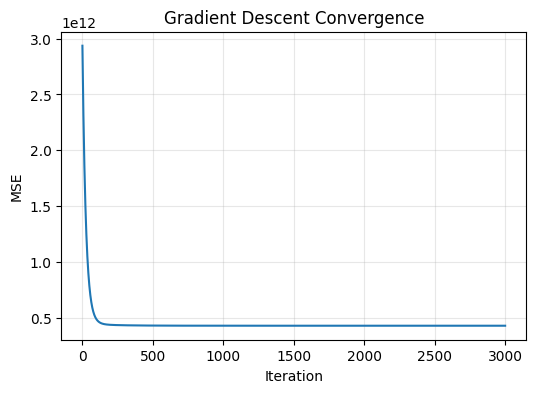

In [ ]:
m, n = X.shape
w_gd = np.zeros(n)  # initialise weights to zero

alpha = 0.01 # learning rate: step size. Too large -> diverges; too small -> very slow
n_iter = 3000
losses = []  # list to track MSE at each iteration (used for the learning curve plot)

# w = w - alpha * (2/m) * X^T (X w - y)
# gradient of MSE w.r.t. w = (2/m) * X^T (X w - y)
for i in range(n_iter):
    y_hat = X @ w_gd  # current predictions with the current weights
    error = y_hat - y
    loss = np.mean(error**2)  # MSE loss
    losses.append(loss)   # saved to plot the convergence curve
    gradient = (2/m) * X.T @ error # gradient of MSE w.r.t. w
    w_gd -= alpha * gradient # update: move opposite to the gradient

y_pred_gd = X @ w_gd

print('Gradient Descent')
print('MSE:', mse(y, y_pred_gd))
print('R2 :', r2(y, y_pred_gd))
print('||w_NE - w_GD|| =', np.linalg.norm(w_ne - w_gd))
# ||w_NE - w_GD||: Euclidean norm of the difference between the two weight vectors
#Learning Curve Gradient Descent

plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('MSE')
plt.title('Gradient Descent Convergence')
plt.grid(True, alpha=0.3)
plt.savefig('gd_convergence.png', dpi=300, bbox_inches='tight')
plt.show()



Comparison between actual values and predicted values


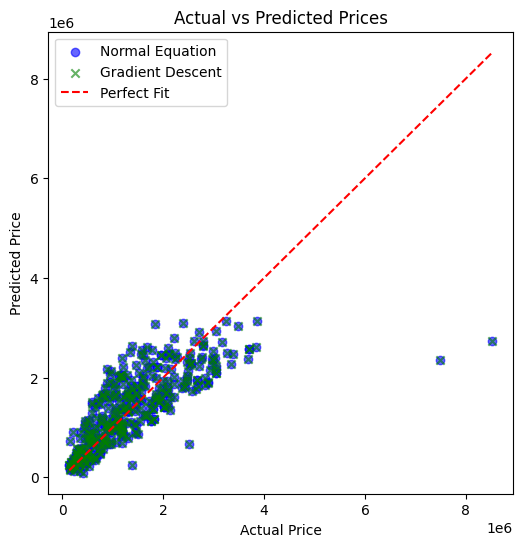

In [9]:
plt.figure(figsize=(6,6))

plt.scatter(
    y, y_pred_ne,
    alpha=0.6,
    color='blue',
    marker='o',
    label='Normal Equation'
)

plt.scatter(
    y, y_pred_gd,
    alpha=0.6,
    color='green',
    marker='x',
    label='Gradient Descent'
)

plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Perfect Fit')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.title('Actual vs Predicted Prices')
plt.show()

Q–Q Plot of Residuals

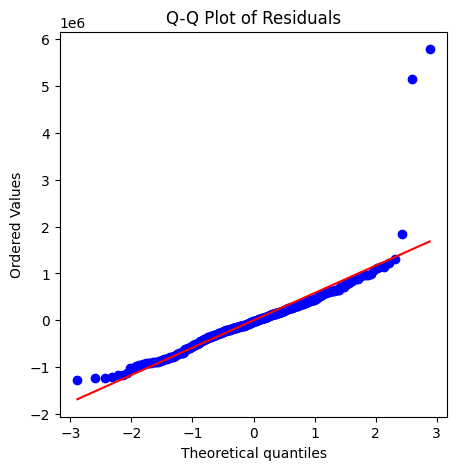

In [ ]:
residuals = y - y_pred_ne
# Q-Q PLOT (Quantile-Quantile): checks the NORMALITY assumption of the residuals
# If points follow the red line -> residuals are approximately normally distributed
plt.figure(figsize=(5,5))
stats.probplot(residuals, dist="norm", plot=plt) # compares empirical vs theoretical N(0,1) quantiles
plt.title('Q-Q Plot of Residuals')
plt.savefig('qq_plot_residuals.png', dpi=300, bbox_inches='tight')
plt.show()

Residuals vs Predicted 

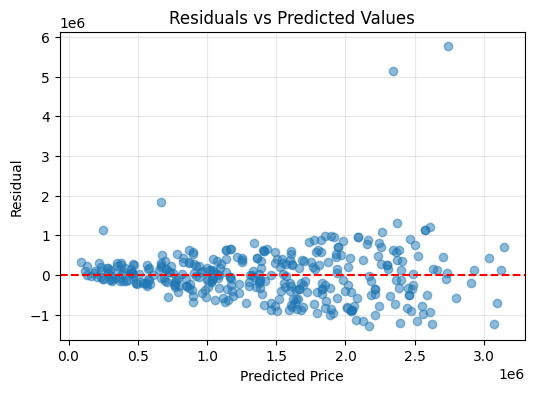

In [11]:
plt.figure(figsize=(6,4))
plt.scatter(y_pred_ne, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Values')
plt.grid(True, alpha=0.3)
plt.savefig('residuals_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()


## Hypothesis Testing

In [ ]:
residuals = y - y_pred_ne
m, n = X.shape

# UNBIASED ESTIMATE OF ERROR VARIANCE (sigma^2)
# Formula: sigma^2 = (RSS) / (m - n)
sigma2 = (residuals @ residuals) / (m - n)

# COVARIANCE MATRIX OF THE COEFFICIENTS
# Formula: Cov(w) = sigma^2 * (X^T X)^{-1}
# The diagonal entries are the variances of each individual coefficient
cov_w = sigma2 * np.linalg.inv(X.T @ X)

# STANDARD ERROR: square root of the variance of each coefficient
# Measures the uncertainty in the estimate of each w_j
se = np.sqrt(np.diag(cov_w))

# T-STATISTIC for each coefficient
# Formula: t_j = w_j / SE(w_j)
# Null hypothesis H0: w_j = 0 (the coefficient does not contribute to the model)
t_stats = w_ne / se
p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=m - n)) # p-value two-tailed:

results = pd.DataFrame({
    'Feature': ['Bias'] + feature_names,
    'Coefficient': w_ne,
    'Std_Error': se,
    't_stat': t_stats,
    'p_value': p_values
}).sort_values('p_value')

results

,Feature,Coefficient,Std_Error,t_stat,p_value
0,Bias,1.406043e+06,35204.521663,39.939263,0.000000
1,area_sqft,7.068269e+05,35727.218832,19.783989,0.000000
5,location_boston,-1.706514e+05,46429.639937,-3.675484,0.000275
7,location_los angeles,-1.834328e+05,51338.032751,-3.573040,0.000403
9,location_new york,-1.721877e+05,50965.601556,-3.378508,0.000812
6,location_chicago,-1.605250e+05,47515.067349,-3.378401,0.000813
10,location_san francisco,-1.746861e+05,51794.976624,-3.372645,0.000829
8,location_miami,-1.320599e+05,43778.035049,-3.016578,0.002747
4,year_built,6.095848e+04,36054.558776,1.690729,0.091794
3,bathrooms,2.557803e+04,35496.092843,0.720587,0.471653


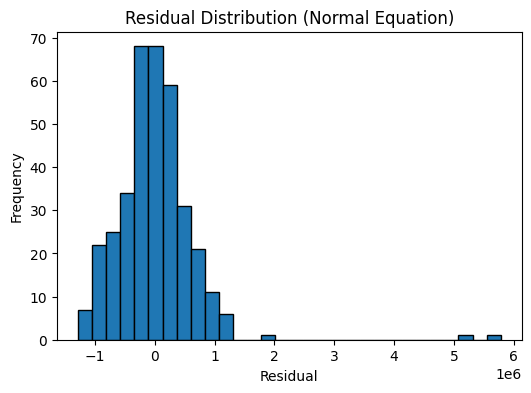

In [ ]:
# RESIDUAL HISTOGRAM: another way to check normality of errors
# We expect a bell-shaped distribution centred on zero
plt.figure(figsize=(6,4))
plt.hist(residuals, bins=30, edgecolor='black')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Residual Distribution (Normal Equation)')
plt.show()




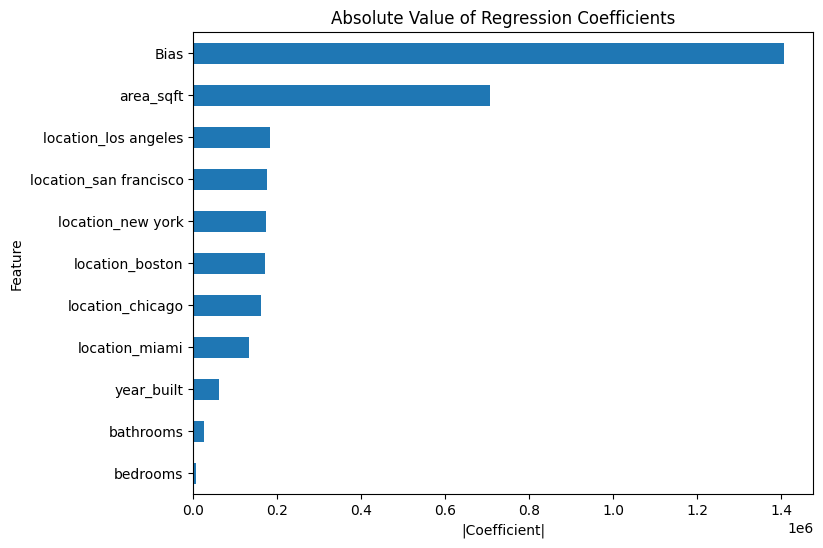

In [ ]:
# ABSOLUTE COEFFICIENT PLOT: relative importance of each feature
# A large absolute coefficient -> larger impact on the predicted price
coef_df = pd.DataFrame({
    'Feature': ['Bias'] + feature_names,
    'Coefficient': w_ne
}).set_index('Feature')

coef_df['Coefficient'].abs().sort_values().plot(kind='barh', figsize=(8,6))
plt.title('Absolute Value of Regression Coefficients')
plt.xlabel('|Coefficient|')
plt.show()


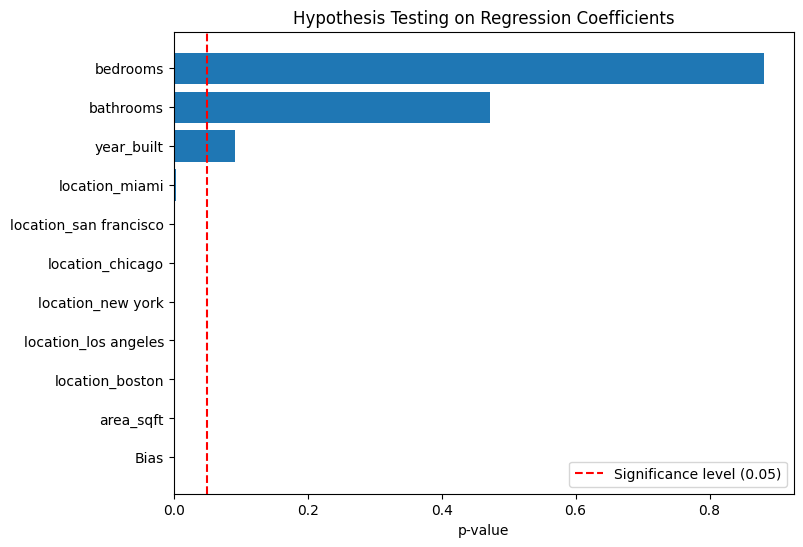

In [ ]:


# P-VALUE PLOT: visualises the statistical significance of each coefficient
# Red dashed line = significance threshold alpha = 0.05
results_sorted = results.sort_values('p_value')

plt.figure(figsize=(8,6))
plt.barh(results_sorted['Feature'], results_sorted['p_value'])
plt.axvline(0.05, color='red', linestyle='--', label='Significance level (0.05)')
plt.xlabel('p-value')
plt.title('Hypothesis Testing on Regression Coefficients')
plt.legend()
plt.show()


## Interpretation

- **p-value < 0.05**: coefficient statistically significant
- **p-value ≥ 0.05**: coefficient statistically not significant
